# Modèle Random Forest

Ce notebook contient l'implémentation et l'évaluation du modèle Random Forest pour prédire l'attrition des employés.

# Introduction aux Forêts Aléatoires (Random Forest)

### Qu'est-ce qu'une Forêt Aléatoire ?

Le **Random Forest** (Forêt Aléatoire) est un algorithme d'apprentissage supervisé puissant, introduit par Leo Breiman en 2001. Il s'agit d'une méthode d'**ensemble**, ce qui signifie qu'elle combine les prédictions de plusieurs modèles (ici, des arbres de décision) pour obtenir un résultat plus stable et précis.

Contrairement à un arbre de décision unique qui peut être instable et sujet au surapprentissage, la forêt utilise la "sagesse des foules" : en agrégeant les décisions de centaines d'arbres indépendants, elle réduit considérablement la variance du modèle global.

### Fonctionnement mathématique et logique

Le fonctionnement du Random Forest repose sur trois piliers fondamentaux :

1. **La brique de base : L'Arbre de Décision**
Chaque arbre divise les données en cherchant à maximiser la pureté des nœuds. On utilise généralement deux critères :
   - **Entropie** : L'entropie mesure le désordre dans les données. Le gain d'information est la réduction de l'entropie après la division des données.
   - **Indice de Gini** :  Mesure de l'impureté des données. Une valeur de 0 indique une pureté maximale, tandis qu'une valeur de 1 indique une impureté maximale.

2. **L'injection d'aléatoire (Bagging & Feature Selection)**
Pour que la forêt soit efficace, chaque arbre doit être différent. On introduit de l'aléatoire de deux manières :
   - **Bootstrap** : Chaque arbre est entraîné sur un échantillon aléatoire des données (tirage avec remplacement).
   - **Sous-espace aléatoire** : À chaque division (split), l'arbre ne choisit pas la meilleure variable parmi toutes, mais seulement parmi un sous-ensemble aléatoire de caractéristiques.

3. **Agrégation des prédictions**
Le résultat final $\hat{y}$ est obtenu en combinant les votes de tous les arbres :
   - **Classification** : Vote majoritaire (la classe la plus fréquente).
   - **Régression** : Moyenne arithmétique des prédictions de tous les arbres

### Avantages du Random Forest

**Réduction du Surapprentissage** : L'agrégation de nombreux arbres compense les erreurs individuelles.  
**Robustesse** : Très performant sur des données complexes, non-linéaires et avec des valeurs aberrantes.  
**Importance des variables** : Permet d'identifier quelles caractéristiques influencent le plus la prédiction.  
**Pas de normalisation** : Contrairement aux modèles linéaires (comme le Perceptron), il ne nécessite pas de mise à l'échelle des données.  
**Données manquantes** : Gère efficacement les valeurs absentes dans les jeux de données.

### Limitations

**Complexité** : L'entraînement de centaines d'arbres demande plus de ressources (mémoire et CPU).  
**Interprétabilité** : Moins visuel qu'un arbre unique (effet "boîte noire").  
**Vitesse** : La prédiction peut être plus lente en temps réel si la forêt contient un très grand nombre d'arbres.


## 1. Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
import pickle

## 2. Chargement des données préparées

In [2]:
# Charger les données préparées
data = pd.read_csv('Data/prepared_data.csv')

# Séparer les caractéristiques et la cible
X = data.drop(columns=["Attrition", "EmployeeID"])
y = data['Attrition']

print(f"Shape des features: {X.shape}")
print(f"Shape de la cible: {y.shape}")
print(f"\nDistribution de la cible:\n{y.value_counts()}")

Shape des features: (4410, 45)
Shape de la cible: (4410,)

Distribution de la cible:
Attrition
0    3699
1     711
Name: count, dtype: int64


## 3. Séparation des données

In [3]:
# Séparation train/test (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Taille ensemble d'entraînement: {X_train.shape[0]}")
print(f"Taille ensemble de test: {X_test.shape[0]}")

Taille ensemble d'entraînement: 3087
Taille ensemble de test: 1323


## 4. Entraînement du modèle Random Forest

Random Forest est un ensemble d'arbres de décision où plusieurs arbres sont créés et entraînés de manière indépendante à partir de sous-ensembles aléatoires des données. Cette approche permet de réduire le risque de sur-apprentissage (overfitting) souvent rencontré avec des arbres de décision individuels, tout en améliorant la précision du modèle.

In [4]:
# Initialisation et entraînement du modèle
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print("Modèle entraîné avec succès!")

Modèle entraîné avec succès!


## 5. Prédictions

In [5]:
# Prédictions sur l'ensemble de test
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

print("Prédictions effectuées!")

Prédictions effectuées!


## 6. Évaluation du modèle

### 6.1 Matrice de confusion

Matrice de Confusion (Random Forest) :
 [[1115    0]
 [  22  186]]


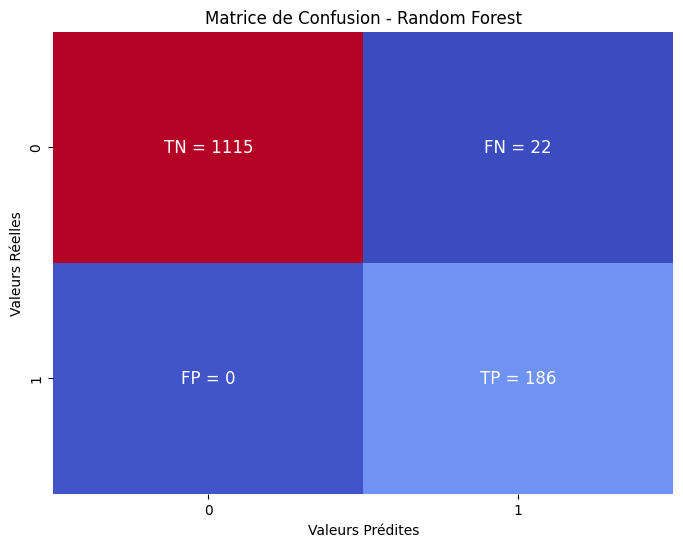

In [6]:
# Matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)
print("Matrice de Confusion (Random Forest) :\n", conf_matrix)

# Visualisation
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=False, fmt="d", cmap="coolwarm", cbar=False)

# Calcul des valeurs TP, TN, FP, FN
TN, FP, FN, TP = conf_matrix.ravel()

# Ajout des valeurs sur le graphique
plt.text(0.5, 0.5, f'TN = {TN}', ha='center', va='center', color='white', fontsize=12)
plt.text(0.5, 1.5, f'FP = {FP}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 0.5, f'FN = {FN}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 1.5, f'TP = {TP}', ha='center', va='center', color='white', fontsize=12)
plt.title("Matrice de Confusion - Random Forest")
plt.ylabel('Valeurs Réelles')
plt.xlabel('Valeurs Prédites')
plt.show()

### 6.2 Rapport de classification

In [7]:
# Rapport de classification
class_report = classification_report(y_test, y_pred)
print("Rapport de Classification (Random Forest) :\n", class_report)

Rapport de Classification (Random Forest) :
               precision    recall  f1-score   support

           0       0.98      1.00      0.99      1115
           1       1.00      0.89      0.94       208

    accuracy                           0.98      1323
   macro avg       0.99      0.95      0.97      1323
weighted avg       0.98      0.98      0.98      1323



### 6.3 Score AUC-ROC

In [8]:
# AUC-ROC
roc_auc = roc_auc_score(y_test, y_proba)
print(f"AUC-ROC (Random Forest) : {roc_auc:.4f}")

AUC-ROC (Random Forest) : 0.9949


### 6.4 Courbe ROC

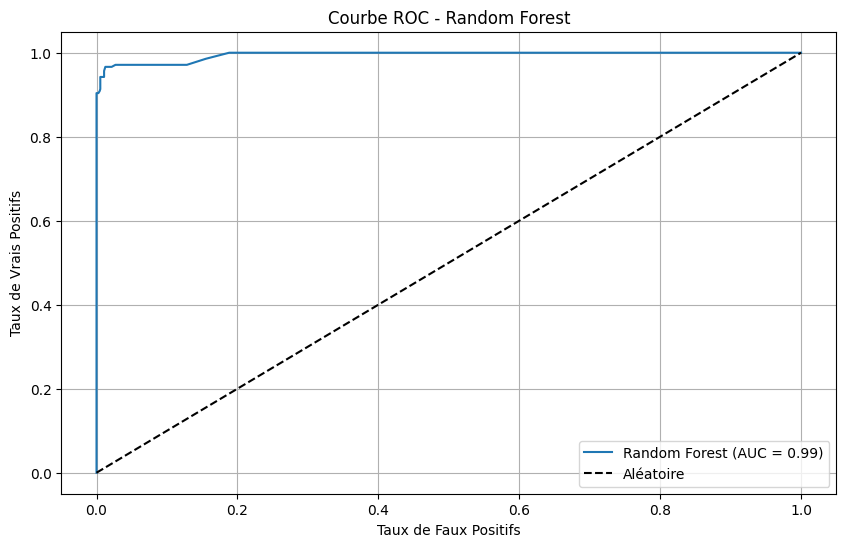

In [9]:
# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Aléatoire")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC - Random Forest")
plt.legend()
plt.grid(True)
plt.show()

## 7. Importance des features

Top 10 features les plus importantes:


                     feature  importance
0   avg_working_time_seconds    0.107698
14         TotalWorkingYears    0.071824
6                        Age    0.071602
10             MonthlyIncome    0.068855
16            YearsAtCompany    0.051683
7           DistanceFromHome    0.047333
12         PercentSalaryHike    0.041431
18      YearsWithCurrManager    0.041302
11        NumCompaniesWorked    0.040394
3    EnvironmentSatisfaction    0.033157


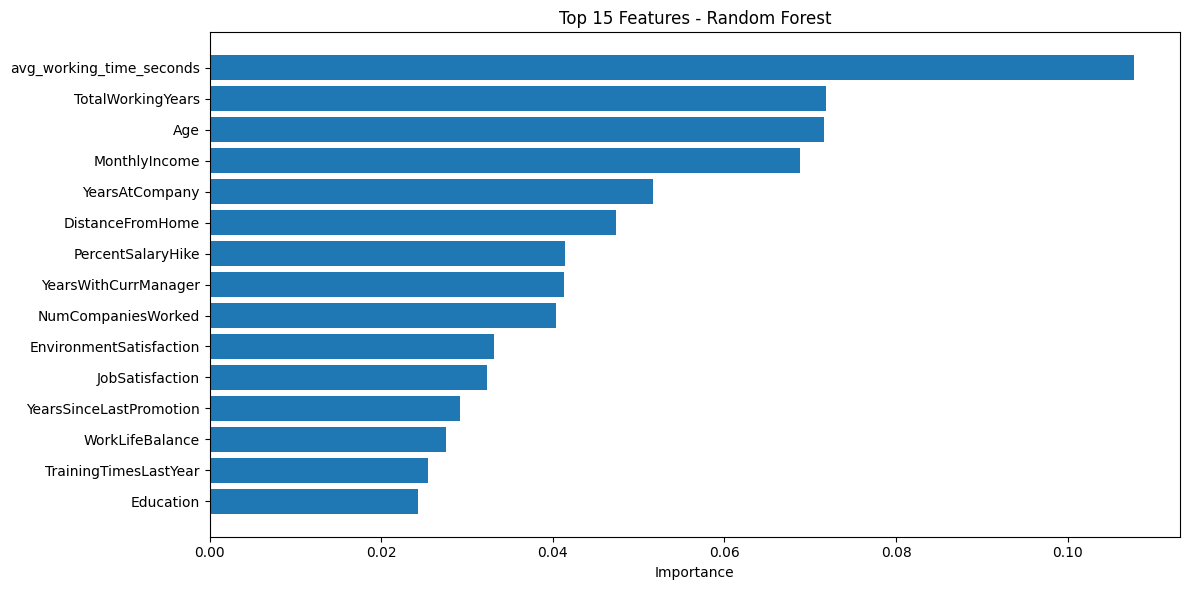

In [10]:
# Affichage de l'importance des features
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print("Top 10 features les plus importantes:")
print(feature_importance.head(10))

# Visualisation
plt.figure(figsize=(12, 6))
plt.barh(feature_importance.head(15)['feature'], feature_importance.head(15)['importance'])
plt.xlabel('Importance')
plt.title('Top 15 Features - Random Forest')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 8. Sauvegarde du modèle et des résultats

In [11]:
# Sauvegarde du modèle
with open('Data/random_forest_model.pkl', 'wb') as f:
    pickle.dump(rf_model, f)

# Sauvegarde des résultats
results = {
    'model_name': 'Random Forest',
    'predictions': y_pred,
    'probabilities': y_proba,
    'auc_roc': roc_auc,
    'confusion_matrix': conf_matrix,
    'feature_importance': feature_importance
}

with open('Data/random_forest_results.pkl', 'wb') as f:
    pickle.dump(results, f)

print("Modèle et résultats sauvegardés!")

Modèle et résultats sauvegardés!


## Résumé

Ce notebook a permis de :
1. Charger les données préparées
2. Entraîner un modèle Random Forest
3. Évaluer ses performances avec plusieurs métriques
4. Analyser l'importance des features
5. Sauvegarder le modèle et les résultats pour comparaison ultérieure